In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from midi_util import convert_midi_to_midi_function
# Load the CSV file
df = pd.read_csv('search_results.csv')
df.head()

,vertical_displacement,horizontal_displacement,beat_per_minutes,similarity
0,0,0,100,0.594137
1,0,0,102,0.609358
2,0,0,104,0.618801
3,0,0,106,0.631584
4,0,0,108,0.637032


Processed 381 note events from signal_b.mid
[    0   100   200   300   400   500   600   700   800   900  1000  1100
  1200  1300  1400  1500  1600  1700  1800  1900  2000  2100  2200  2300
  2400  2500  2600  2700  2800  2900  3000  3100  3200  3300  3400  3500
  3600  3700  3800  3900  4000  4100  4200  4300  4400  4500  4600  4700
  4800  4900  5000  5100  5200  5300  5400  5500  5600  5700  5800  5900
  6000  6100  6200  6300  6400  6500  6600  6700  6800  6900  7000  7100
  7200  7300  7400  7500  7600  7700  7800  7900  8000  8100  8200  8300
  8400  8500  8600  8700  8800  8900  9000  9100  9200  9300  9400  9500
  9600  9700  9800  9900 10000 10100 10200 10300 10400 10500 10600 10700
 10800 10900 11000 11100 11200 11300 11400 11500 11600 11700 11800 11900
 12000 12100 12200 12300 12400 12500 12600 12700 12800 12900 13000 13100
 13200 13300 13400 13500 13600 13700 13800 13900 14000 14100 14200 14300
 14400 14500 14600 14700 14800 14900 15000 15100 15200 15300 15400 15500
 15600 

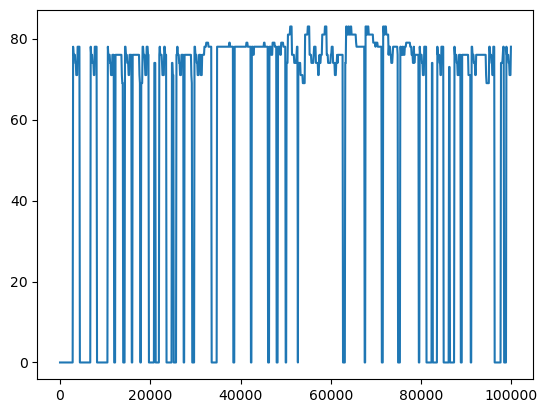

In [65]:
midi_function = convert_midi_to_midi_function('signal_b.mid')

x = np.arange(0, 100000, 100)
print(x)
y = []
for i in x:
    kelvin = midi_function(i) 
    if len(kelvin) > 0: 
        y.append(kelvin[0]) 
    else: 
        y.append(0) 
# plt.plot(x, y) 
print(y)
plt.plot(x, y)

In [66]:
x_axis = df['horizontal_displacement'] 
y_axis = df['beat_per_minutes'] 
z_axis = df['similarity'] 

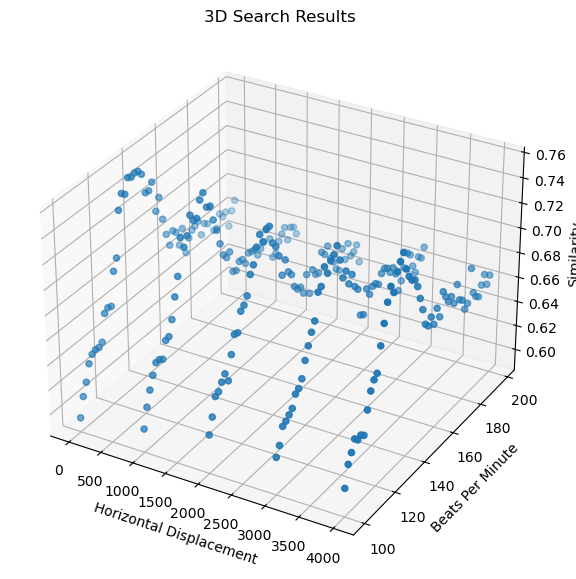

In [67]:
def plot_3d(x_data, y_data, z_data, title="3D Plot", xlabel="X", ylabel="Y", zlabel="Z"):
    """
    Plots 3D data using matplotlib
    
    Parameters:
    x_data, y_data, z_data: Arrays of data points
    title: Plot title (optional)
    xlabel, ylabel, zlabel: Axis labels (optional)
    """
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d import Axes3D
    
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')
    
    ax.scatter(x_data, y_data, z_data)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_zlabel(zlabel)
    
    plt.show()
plot_3d(x_axis, y_axis, z_axis, title="3D Search Results", xlabel="Horizontal Displacement", ylabel="Beats Per Minute", zlabel="Similarity")


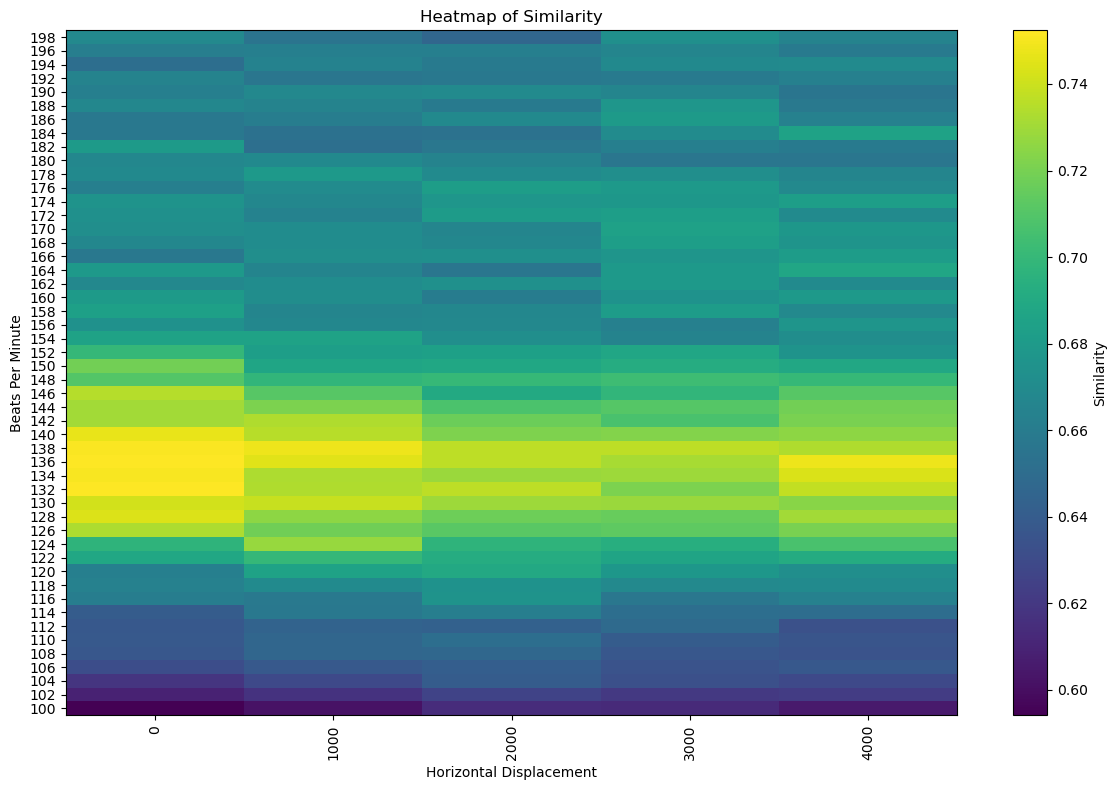

In [69]:
# Create a pivot table for the heatmap
heatmap_data = df.pivot_table(
    index='beat_per_minutes',
    columns='horizontal_displacement',
    values='similarity'
)

plt.figure(figsize=(12, 8))
plt.imshow(heatmap_data, aspect='auto', origin='lower', cmap='viridis')
plt.colorbar(label='Similarity')
plt.xlabel('Horizontal Displacement')
plt.ylabel('Beats Per Minute')
plt.title('Heatmap of Similarity')
plt.xticks(
    ticks=np.arange(len(heatmap_data.columns)),
    labels=heatmap_data.columns,
    rotation=90
)
plt.yticks(
    ticks=np.arange(len(heatmap_data.index)),
    labels=np.round(heatmap_data.index, 1)
)
plt.tight_layout()
plt.show()